In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import torch
from torch.utils.data import DataLoader
from math import sqrt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error

%matplotlib inline

In [ ]:
# We set a fixed seed for repeatability
random_seed = 12345  # This seed is also used in the pandas sample() method below
torch.manual_seed(random_seed)

# Your first task as a Data Scientist
You just started in your new job as Data Scientist at Awesome Corp. One of the customers recently had a temporary sensor failure causing the loss of very valuable flow rate data. They need an accurate estimate of the missing flow rates ASAP so that they can optimize their system. Naturally, you are given the job since you have mastered deep learning.

### Here is the brief!

You need to estimate the total flow of oil, gas, and water through a choke valve. The total flow rate is labeled `QTOT`. You should use all measurements that may explain the total flow. Awesome Corp has already prepared these for you in a dataset (no further preprocessing is required). The measurements (features) are labeled as follows:
- `CHK`: choke opening - a number in [0, 1], 1 meaning fully open and 0 meaning closed
- `PWH`: pressure upstream the choke (scaled)
- `PDC`: pressure downstream the choke (scaled)
- `TWH`: temperature upstream the choke (scaled)
- `FGAS`: fraction of gas to total flow - a number in [0,1]
- `FOIL`: fraction of oil to total flow - a number in [0,1]

The location of the sensors are shown in the figure below.

<img src="well_sensors.png">

### Wait! There is one issue. The customer does not have a model for the total flow rate...

A simple choke model for water flow is:
$$QTOT = C_v(CHK) \sqrt{\frac{2(PWH - PDC)}{\rho}}$$
where $C_v(CHK)$ gives the cross-sectional area as a function of choke opening `CHK`.

Unfortunately, there are complications that prevent us from using this model:

1. We do not know what the correct equations are for multi-phase flow. For example, we expect gas expansions to be a factor. This factor is likely dependent on the temperature `TWH` and the amount of gas `FGAS`. Viscosity is probably a factor too, and that would depend on `FOIL`.
2. We do not know the form of the choke $C_v$-curve.

[Head scratch] Perhaps we can use a deep learning algorithm to learn a good representation of the data? Let us try to use all the available measurements to model `QTOT` using a neural network:
$$QTOT = f_{\theta}(CHK, PWH, PDC, TWH, FGAS, FOIL)$$

Let's get to work!

# Load the dataset

In [ ]:
df = pd.read_csv('../data/well_data.csv', index_col=0)
print(df)
# print(df.describe())

# Plot the features

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(16, 9))

# Choke valve opening
ax[0, 0].plot(df['CHK'], label='CHK')
ax[0, 0].legend()

# Total flow through choke valve
ax[0, 1].plot(df['TWH'], label='TWH')
ax[0, 1].legend()

# Diff pressure over choke valve
ax[1, 0].plot(df['PWH'] - df['PDC'], label='PWH - PDC')
ax[1, 0].legend()

# Fractions
ax[1, 1].plot(df['FOIL'], label='FOIL')
ax[1, 1].plot(df['FGAS'], '--r', label='FGAS')
ax[1, 1].legend()

# Split the data into a train, validation and test set

Our test set consists of the examples indexed by [2000, 2499]. Our task is to estimate `QTOT` for this period.

The rest of the data is split into a train (90%) and validation set (10%). We draw the validation data randomly.

In [ ]:
# Test set (this is the period for which we must estimate QTOT)
test_set = df.iloc[2000:2500]

# Make a copy of the dataset and remove the test data
train_val_set = df.copy().drop(test_set.index)

# Sample validation data without replacement (20%)
val_set = train_val_set.sample(frac=0.2, replace=False, random_state=random_seed)

# The remaining data is used for training (80%)
train_set = train_val_set.copy().drop(val_set.index)

# Check that the numbers add up
n_points = len(train_set) + len(val_set) + len(test_set)
print(f'{len(df)} = {len(train_set)} + {len(val_set)} + {len(test_set)} = {n_points}')

# Plot the train, validation and test set

In [ ]:
plt.figure(figsize=(16, 9))
plt.scatter(train_set.index, train_set['QTOT'], color='black', label='Train')
plt.scatter(val_set.index, val_set['QTOT'], color='green', label='Val')
plt.scatter(test_set.index, test_set['QTOT'], color='red', label='Test')
plt.legend()

# Neural network

Here we specify how to construct our neural network $f_{\theta}$. 

We use ReLU activation for the hidden layers:
$$h^{(i)} = ReLU(W^{(i)} h^{(i-1)} + b^{(i)})$$

The output layer is a simple linear layer since we will solve a regression problem.

We use He initialization for the weights. The biases are initialized to zero.

In [ ]:
class Net(torch.nn.Module):
    """
    PyTorch offers several ways to construct neural networks.
    Here we choose to implement the network as a Module class.
    This gives us full control over the construction and clarifies our intentions.
    """
    
    def __init__(self, layers):
        """
        Constructor of neural network
        :param layers: list of layer widths. Note that len(layers) = network depth + 1 since we incl. the input layer.
        """
        super().__init__()

        self.device = 'cuda' if torch.cuda.is_available() else 'cpu'

        assert len(layers) >= 2, "At least two layers are required (incl. input and output layer)"
        self.layers = layers

        # Fully connected linear layers
        linear_layers = []

        for i in range(len(self.layers) - 1):
            n_in = self.layers[i]
            n_out = self.layers[i+1]
            layer = torch.nn.Linear(n_in, n_out)

            # Initialize weights and biases
            a = 1 if i == 0 else 2
            layer.weight.data = torch.randn((n_out, n_in)) * sqrt(a / n_in)
            layer.bias.data = torch.zeros(n_out)
            
            # Add to list
            linear_layers.append(layer)
        
        # Modules/layers must be registered to enable saving of model
        self.linear_layers = torch.nn.ModuleList(linear_layers)  

        # Non-linearity (e.g. ReLU, ELU, or SELU)
        self.act = torch.nn.ReLU(inplace=False)

    def forward(self, input):
        """
        Forward pass to evaluate network for input values
        :param input: tensor assumed to be of size (batch_size, n_inputs)
        :return: output tensor
        """
        x = input
        for l in self.linear_layers[:-1]:
            x = l(x) # Wx + b
            x = self.act(x) # ReLu(Wx + b)

        output_layer = self.linear_layers[-1]
        return output_layer(x)

    def get_num_parameters(self):
        return sum(p.numel() for p in self.parameters())

    def save(self, path: str):
        """
        Save model state
        :param path: Path to save model state
        :return: None
        """
        torch.save({
            'model_state_dict': self.state_dict(),
        }, path)

    def load(self, path: str):
        """
        Load model state from file
        :param path: Path to saved model state
        :return: None
        """
        checkpoint = torch.load(path, map_location=torch.device("cuda" if torch.cuda.is_available() else "cpu"))
        self.load_state_dict(checkpoint['model_state_dict'])

# Training loop

Below we implement the training procedure for the neural network. 

We loop over batches in the dataset (one pass through the dataset is called an _epoch_).

For each batch B, we do a forward pass to compute the cost function:
$$J(\theta) = \frac{1}{|B|} \sum_{i \in B} (y_i - f_{\theta}(x_i))^2 + \lambda \lVert \theta \rVert_2^2$$

We then do a backward pass to compute the gradient:
$$\frac{\partial J}{\partial \theta}$$

Finally, we update the parameters:
$$\theta \leftarrow \theta - \alpha \frac{\partial J}{\partial \theta}$$

Note that we use Adam so the update rule is actually a bit different than the one above.

In [ ]:
def train(
        net: torch.nn.Module,
        train_loader: DataLoader,
        val_loader: DataLoader,
        n_epochs: int,
        lr: float,
        l2_reg: float,
) -> torch.nn.Module:
    """
    Train model using mini-batch SGD
    After each epoch, we evaluate the model on validation data

    :param net: initialized neural network
    :param train_loader: DataLoader containing training set
    :param n_epochs: number of epochs to train
    :param lr: learning rate (default: 0.001)
    :param l2_reg: L2 regularization factor (default: 0)
    :return: torch.nn.Module: trained model.
    """

    # Define loss and optimizer
    criterion = torch.nn.MSELoss(reduction='mean')
    optimizer = torch.optim.Adam(net.parameters(), lr=lr)

    # Train Network
    for epoch in range(n_epochs):
        for inputs, labels in train_loader:
            # Zero the parameter gradients (from last iteration)
            optimizer.zero_grad()

            # Forward propagation
            outputs = net(inputs)
            
            # Compute cost function
            batch_mse = criterion(outputs, labels)
            
            reg_loss = 0
            for param in net.parameters():
                reg_loss += param.pow(2).sum()

            cost = batch_mse + l2_reg * reg_loss

            # Backward propagation to compute gradient
            cost.backward()
            
            # Update parameters using gradient
            optimizer.step()
        
        # Evaluate model on validation data
        mse_val = 0
        for inputs, labels in val_loader:
            mse_val += torch.sum(torch.pow(labels - net(inputs), 2)).item()
        mse_val /= len(val_loader.dataset)
        print(f'Epoch: {epoch + 1}: Val MSE: {mse_val}')
        
    return net

# Early stopping Class

This implementation is inspired by this article: https://medium.com/biased-algorithms/a-practical-guide-to-implementing-early-stopping-in-pytorch-for-model-training-99a7cbd46e9d

In [ ]:
class EarlyStopping:
    def __init__(self, patience=5, delta=0, verbose=False):
        self.patience = patience
        self.delta = delta
        self.verbose = verbose
        self.best_loss = None
        self.no_improvement_count = 0
        self.stop_training = False
    
    def check_early_stop(self, val_loss):
        if self.best_loss is None or val_loss < self.best_loss - self.delta:
            self.best_loss = val_loss
            self.no_improvement_count = 0
        else:
            self.no_improvement_count += 1
            if self.no_improvement_count >= self.patience:
                self.stop_training = True
                if self.verbose:
                    print("Stopping early as no improvement has been observed.")


In [ ]:
# Implementing training with early stopping

from copy import deepcopy

def train_early_stopping(
    net, train_loader, val_loader, n_epochs, lr, l2_reg, early_stopping
):
    criterion = torch.nn.MSELoss(reduction="mean")
    optimizer = torch.optim.Adam(net.parameters(), lr=lr)

    history = {"train_mse": [], "val_mse": []}
    best_epoch = 0
    best_state = deepcopy(net.state_dict())

    for epoch in range(n_epochs):
        net.train()

        for inputs, labels in train_loader:
            optimizer.zero_grad()
            outputs = net(inputs)

            batch_mse = criterion(outputs, labels)
            reg_loss = sum(param.pow(2).sum() for param in net.parameters())
            cost = batch_mse + l2_reg * reg_loss

            cost.backward()
            optimizer.step()

        # Measure train and validation MSE without gradients or regularization.
        net.eval()
        train_squared_error = 0.0
        train_count = 0
        val_squared_error = 0.0
        val_count = 0

        with torch.no_grad():
            for inputs, labels in train_loader:
                train_squared_error += torch.sum(torch.pow(labels - net(inputs), 2)).item()
                train_count += labels.numel()

            for inputs, labels in val_loader:
                val_squared_error += torch.sum(torch.pow(labels - net(inputs), 2)).item()
                val_count += labels.numel()

        train_mse = train_squared_error / train_count
        val_mse = val_squared_error / val_count

        history["train_mse"].append(train_mse)
        history["val_mse"].append(val_mse)

        # print(
        #     f"Epoch {epoch + 1}: train MSE={train_mse:.4f}, "
        #     f"val MSE={val_mse:.4f}"
        # )

        # Check improvement before the class updates best_loss.
        previous_best = early_stopping.best_loss
        improved = (
            previous_best is None
            or val_mse < previous_best - early_stopping.delta
        )

        early_stopping.check_early_stop(val_mse)

        if improved:
            best_epoch = epoch + 1
            best_state = deepcopy(net.state_dict())

        if early_stopping.stop_training:
            if early_stopping.verbose:
                print(f"Best epoch was {best_epoch}.")
            break

    # Return the best-validation model, not just the final epoch's model.
    net.load_state_dict(best_state)
    return net, history, best_epoch

# Prepare data for training

We use the PyTorch DataLoader to simplify the partitioning of the training data into batches.

In [29]:
# Define the target and features
INPUT_COLS = ['CHK', 'PWH', 'PDC', 'TWH', 'FGAS', 'FOIL']
OUTPUT_COLS = ['QTOT']

# Get input and output tensors and convert them to torch tensors
x_train = torch.from_numpy(train_set[INPUT_COLS].values).to(torch.float)
y_train = torch.from_numpy(train_set[OUTPUT_COLS].values).to(torch.float)

x_val = torch.from_numpy(val_set[INPUT_COLS].values).to(torch.float)
y_val = torch.from_numpy(val_set[OUTPUT_COLS].values).to(torch.float)

# Create dataset loaders
# Here we specify the batch size and if the data should be shuffled
train_dataset = torch.utils.data.TensorDataset(x_train, y_train)
generator = torch.Generator().manual_seed(random_seed)  # For reproducibility
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=10, shuffle=True, generator=generator)

val_dataset = torch.utils.data.TensorDataset(x_val, y_val)
val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=len(val_set), shuffle=False)

# Construct and initialize the model

The time to construct an actual neural network has finally come! 

Now, what should the network size be? How much data do we have? How nonlinear is the underlying function we are trying to model? Two to hidden layers with 50 units may be sufficient? Let's try that.

In [ ]:

layers = [len(INPUT_COLS), 16, 16, len(OUTPUT_COLS)]
initial_model = Net(layers)
net_no_reg = deepcopy(initial_model)
net_with_l2_reg = deepcopy(initial_model)
net_with_l2_early_stopping_reg = deepcopy(initial_model)

print(f'Layers: {layers}')
print(f'Number of model parameters: {initial_model.get_num_parameters()}')

Layers: [6, 16, 16, 1]
Number of model parameters: 401


## Linear regression model

In [45]:
## Create linear model as baseline for comparison
linear_model = LinearRegression()
linear_model.fit(train_set[INPUT_COLS], train_set[OUTPUT_COLS])
linear_predictions = linear_model.predict(val_set[INPUT_COLS])

baseline_val_mse = mean_squared_error(val_set[OUTPUT_COLS], linear_predictions)
baseline_val_mae = mean_absolute_error(val_set[OUTPUT_COLS], linear_predictions)

print("Linear model validation MSE:", baseline_val_mse)
print("Linear model validation MAE:", baseline_val_mae)

Linear model validation MSE: 8.417497942118704
Linear model validation MAE: 2.2292529695194143


# Train the model

Almost there. We only need to set some important hyper-parameters before we start the training. The number of epochs to train, the learning rate, and the L2 regularization factor.

In [32]:
# Train without regularization (l2 and early stopping)
n_epochs = 800
lr = 0.001
net_no_reg = train(
    net=net_no_reg,
    train_loader=train_loader,
    val_loader=val_loader,
    n_epochs=n_epochs,
    lr=lr,
    l2_reg=0.0,  # No L2 regularization
)


Epoch: 1: Val MSE: 510.9252403846154
Epoch: 2: Val MSE: 44.410220102163464
Epoch: 3: Val MSE: 26.74695763221154
Epoch: 4: Val MSE: 15.825698617788461
Epoch: 5: Val MSE: 11.122523850661057
Epoch: 6: Val MSE: 9.337127216045673
Epoch: 7: Val MSE: 8.456521371694711
Epoch: 8: Val MSE: 7.678982309194711
Epoch: 9: Val MSE: 7.220391845703125
Epoch: 10: Val MSE: 6.88758779672476
Epoch: 11: Val MSE: 6.669266451322115
Epoch: 12: Val MSE: 6.666349909855769
Epoch: 13: Val MSE: 6.403830190805288
Epoch: 14: Val MSE: 6.501582688551682
Epoch: 15: Val MSE: 6.210429030198317
Epoch: 16: Val MSE: 6.0861980731670675
Epoch: 17: Val MSE: 6.087863393930289
Epoch: 18: Val MSE: 6.0676185021033655
Epoch: 19: Val MSE: 6.1474999060997595
Epoch: 20: Val MSE: 5.952469576322115
Epoch: 21: Val MSE: 5.964153583233173
Epoch: 22: Val MSE: 6.4392287034254805
Epoch: 23: Val MSE: 5.8760986328125
Epoch: 24: Val MSE: 6.023768967848557
Epoch: 25: Val MSE: 6.1800283578725965
Epoch: 26: Val MSE: 5.790462083082932
Epoch: 27: Val M

Epoch 1: train MSE=674.9127, val MSE=700.0895
Epoch 2: train MSE=102.3143, val MSE=108.8598
Epoch 3: train MSE=57.3086, val MSE=59.4303
Epoch 4: train MSE=37.3925, val MSE=38.9876
Epoch 5: train MSE=21.4254, val MSE=22.2373
Epoch 6: train MSE=12.5383, val MSE=12.8645
Epoch 7: train MSE=9.5916, val MSE=9.6818
Epoch 8: train MSE=8.4508, val MSE=8.4630
Epoch 9: train MSE=7.6631, val MSE=7.6478
Epoch 10: train MSE=7.3258, val MSE=7.2948
Epoch 11: train MSE=6.9126, val MSE=6.8301
Epoch 12: train MSE=6.8719, val MSE=6.6835
Epoch 13: train MSE=6.4960, val MSE=6.3297
Epoch 14: train MSE=6.4055, val MSE=6.2354
Epoch 15: train MSE=6.3171, val MSE=6.1529
Epoch 16: train MSE=6.2995, val MSE=6.1294
Epoch 17: train MSE=6.2656, val MSE=6.0597
Epoch 18: train MSE=6.1738, val MSE=6.0064
Epoch 19: train MSE=6.2239, val MSE=6.0690
Epoch 20: train MSE=6.4034, val MSE=6.2374
Epoch 21: train MSE=6.2143, val MSE=6.0215
Epoch 22: train MSE=6.2272, val MSE=6.0899
Epoch 23: train MSE=6.0126, val MSE=5.8348
Epoc

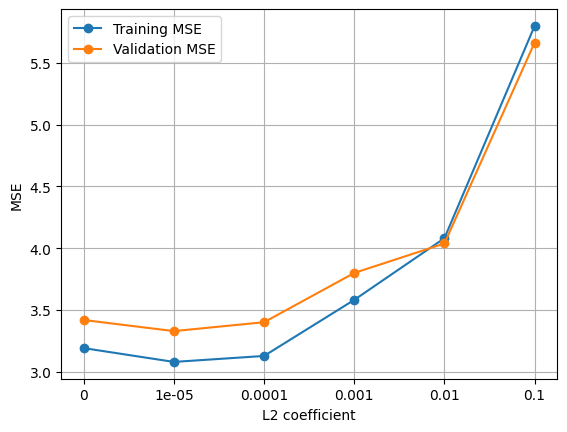

In [46]:
## Sweep over different values for L2 regularization factor
l2_values = [0, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
n_epochs = 800
results = {}

for l2 in l2_values:
    model = deepcopy(initial_model)

    # Reset the shuffle sequence so each run gets the same batch order.
    generator = torch.Generator().manual_seed(random_seed)
    run_train_loader = DataLoader(
        train_dataset,
        batch_size=10,
        shuffle=True,
        generator=generator,
    )

    # Patience > n_epochs means all runs complete the same number of epochs.
    early_stopping = EarlyStopping(
        patience=n_epochs + 1,
        delta=0,
        verbose=False,
    )

    _, history, _ = train_early_stopping(
        model,
        run_train_loader,
        val_loader,
        n_epochs,
        lr,
        l2,
        early_stopping,
    )

    # Compare MSE at the same final epoch; these are unregularized MSE metrics.
    results[l2] = {
        "train_mse": history["train_mse"][-1],
        "val_mse": history["val_mse"][-1],
    }

x = range(len(l2_values))
plt.plot(x, [results[l2]["train_mse"] for l2 in l2_values],
         marker="o", label="Training MSE")
plt.plot(x, [results[l2]["val_mse"] for l2 in l2_values],
         marker="o", label="Validation MSE")
plt.xticks(list(x), [f"{l2:g}" for l2 in l2_values])
plt.xlabel("L2 coefficient")
plt.ylabel("MSE")
plt.legend()
plt.grid(True)
plt.show()

In [47]:
## With early stopping

# Initialize early stopping
patience = 10  # epochs to wait after no improvement
delta = 0.01  # minimum change in the monitored metric
early_stopping = EarlyStopping(patience=patience, delta=delta, verbose=True)

n_epochs = 800
lr = 0.001
l2_reg = 1e-5
net_with_l2_early_stopping_reg, history, best_epoch = train_early_stopping(
    net_with_l2_early_stopping_reg, train_loader, val_loader, n_epochs, lr, l2_reg, early_stopping
)

Epoch 1: train MSE=665.4837, val MSE=690.6148
Epoch 2: train MSE=90.7000, val MSE=95.3636
Epoch 3: train MSE=69.1988, val MSE=71.6632
Epoch 4: train MSE=52.4710, val MSE=53.5659
Epoch 5: train MSE=34.8680, val MSE=35.7679
Epoch 6: train MSE=21.5334, val MSE=21.9457
Epoch 7: train MSE=13.3606, val MSE=13.5034
Epoch 8: train MSE=10.2797, val MSE=10.2120
Epoch 9: train MSE=9.0007, val MSE=8.8850
Epoch 10: train MSE=8.3446, val MSE=8.2272
Epoch 11: train MSE=7.8218, val MSE=7.6439
Epoch 12: train MSE=7.4456, val MSE=7.2451
Epoch 13: train MSE=7.2077, val MSE=6.9989
Epoch 14: train MSE=6.9197, val MSE=6.7312
Epoch 15: train MSE=6.6945, val MSE=6.4759
Epoch 16: train MSE=6.6788, val MSE=6.3701
Epoch 17: train MSE=6.6257, val MSE=6.3981
Epoch 18: train MSE=6.4577, val MSE=6.1893
Epoch 19: train MSE=6.2892, val MSE=5.9565
Epoch 20: train MSE=6.2427, val MSE=5.8745
Epoch 21: train MSE=6.2238, val MSE=5.8481
Epoch 22: train MSE=6.3555, val MSE=5.9459
Epoch 23: train MSE=6.8681, val MSE=6.5724
Ep

# Evaluate the model on validation data

In [ ]:
# Predict on validation data
pred_val_no_reg = net_no_reg(x_val)
pred_val_with_l2_reg = net_with_l2_reg(x_val)
pred_val_with_l2_early_stopping_reg = net_with_l2_early_stopping_reg(x_val)

# Compute MSE, MAE and MAPE on validation data
print('Error on validation data')

# No regularization
mse_val_no_reg = torch.mean(torch.pow(pred_val_no_reg - y_val, 2))
print(f'MSE (no reg): {mse_val_no_reg.item()}')

mae_val_no_reg = torch.mean(torch.abs(pred_val_no_reg - y_val))
print(f'MAE (no reg): {mae_val_no_reg.item()}')

mape_val_no_reg = 100*torch.mean(torch.abs(torch.div(pred_val_no_reg - y_val, y_val)))
print(f'MAPE (no reg): {mape_val_no_reg.item()} %')

# # With L2 regularization
# mse_val_with_l2_reg = torch.mean(torch.pow(pred_val_with_l2_reg - y_val, 2))
# print(f'MSE (with L2 reg): {mse_val_with_l2_reg.item()}') 

# mae_val_with_l2_reg = torch.mean(torch.abs(pred_val_with_l2_reg - y_val))
# print(f'MAE (with L2 reg): {mae_val_with_l2_reg.item()}')

# mape_val_with_l2_reg = 100*torch.mean(torch.abs(torch.div(pred_val_with_l2_reg - y_val, y_val)))
# print(f'MAPE (with L2 reg): {mape_val_with_l2_reg.item()} %')

# With L2 regularization and early stopping
mse_val_with_l2_early_stopping_reg = torch.mean(torch.pow(pred_val_with_l2_early_stopping_reg - y_val, 2))
print(f'MSE (with L2 reg and early stopping): {mse_val_with_l2_early_stopping_reg.item()}')     

mae_val_with_l2_early_stopping_reg = torch.mean(torch.abs(pred_val_with_l2_early_stopping_reg - y_val))
print(f'MAE (with L2 reg and early stopping): {mae_val_with_l2_early_stopping_reg.item()}')

mape_val_with_l2_early_stopping_reg = 100*torch.mean(torch.abs(torch.div(pred_val_with_l2_early_stopping_reg - y_val, y_val)))
print(f'MAPE (with L2 reg and early stopping): {mape_val_with_l2_early_stopping_reg.item()} %')

Error on validation data
MSE (no reg): 1198.65966796875
MAE (no reg): 33.38455581665039
MAPE (no reg): 100.10572814941406 %
MSE (with L2 reg): 1198.65966796875
MAE (with L2 reg): 33.38455581665039
MAPE (with L2 reg): 100.10572814941406 %
MSE (with L2 reg and early stopping): 4.1844611167907715
MAE (with L2 reg and early stopping): 1.4027196168899536
MAPE (with L2 reg and early stopping): 5.4592366218566895 %


Plotting the validation error against the baseline model's validation error (MSE)

baseline_val_mse: 8.417497942118704


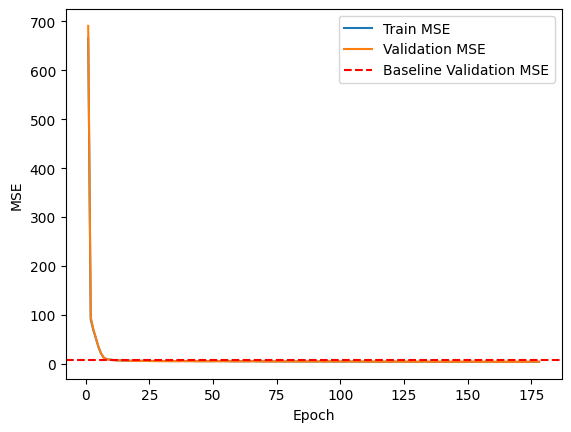

In [53]:
epochs = range(1, len(history["train_mse"]) + 1)
print("baseline_val_mse:", baseline_val_mse)

plt.plot(epochs, history["train_mse"], label="Train MSE")
plt.plot(epochs, history["val_mse"], label="Validation MSE")
plt.axhline(y=baseline_val_mse, color='r', linestyle='--', label='Baseline Validation MSE')
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()

# Are you happy with the result? 

Remember that the validation error is just an estimate of the test error (the error on new examples). The test error may be higher or lower. We may proceed if we believe that we have a good validation set and the validation error is sufficiently low.

If we wish to proceed, a final step before we produce our estimates would be to re-train the model on both the train and validation data. We will skip this step for now.

Let's see how well we did!

# Re-training the model on train and validation data

In [ ]:
x_train_val = torch.from_numpy(train_val_set[INPUT_COLS].values).to(torch.float)
y_train_val = torch.from_numpy(train_val_set[OUTPUT_COLS].values).to(torch.float)

train_dataset = torch.utils.data.TensorDataset(x_train_val, y_train_val)
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=10, shuffle=True)

test_net = Net(layers)
test_net = train(test_net, train_loader, val_loader, best_epoch, lr, l2_reg)

# Evaluate the model on test data

In [ ]:
# Get input and output as torch tensors
x_test = torch.from_numpy(test_set[INPUT_COLS].values).to(torch.float)
y_test = torch.from_numpy(test_set[OUTPUT_COLS].values).to(torch.float)

# Make prediction
pred_test = net(x_test)

# Compute MSE, MAE and MAPE on test data
print('Error on test data')

mse_test = torch.mean(torch.pow(pred_test - y_test, 2))
print(f'MSE: {mse_test.item()}')

mae_test = torch.mean(torch.abs(pred_test - y_test))
print(f'MAE: {mae_test.item()}')

mape_test = 100*torch.mean(torch.abs(torch.div(pred_test - y_test, y_test)))
print(f'MAPE: {mape_test.item()} %')

# Visual evaluation

In [ ]:
plt.figure(figsize=(16, 9))
plt.plot(y_test.numpy(), label='Missing QTOT')
plt.plot(pred_test.detach().numpy(), label='Estimated QTOT')
plt.legend()

# That's pretty good! 

But this is only the beginning. We have only set up the framework. Now you can be creative and experiment with different architectures, regularization techniques and hyper-parameters. I challenge you not to keep staring at those training curves as you wait for the result of a cool new idea - I am still hypnotized by them :-)